In [1]:
import os
import numpy as np
import pandas as pd


# Define paths
base_path = r"D:\Uni\ترم 5\Statistics\Projects"
demo_path = os.path.join(base_path, "DEMO_L.xpt")
alq_path = os.path.join(base_path, "ALQ_L.xpt")
dpq_path = os.path.join(base_path, "DPQ_L.xpt")


# Loading data
df_demo = pd.read_sas(demo_path)
df_alq = pd.read_sas(alq_path)
df_dpq = pd.read_sas(dpq_path)


# Ensure SEQN is integer
for df in [df_demo, df_alq, df_dpq]:
    df['SEQN'] = df['SEQN'].astype(int)


# 1. Process DPQ (Depression)
dpq_cols = [f"DPQ{str(i).zfill(3)}" for i in range(10, 100, 10)]
for col in dpq_cols:
    if col in df_dpq.columns:
        df_dpq[col] = df_dpq[col].replace({7: np.nan, 9: np.nan})


df_dpq['PHQ9_Score'] = df_dpq[dpq_cols].sum(axis=1, skipna=False)
df_dpq['Depression_Event_A'] = (df_dpq['PHQ9_Score'] > 9).astype(float)
df_dpq.loc[df_dpq['PHQ9_Score'].isna(), 'Depression_Event_A'] = np.nan


# 2. Process ALQ (Alcohol)
df_alq['ALQ270'] = df_alq['ALQ270'].replace([77, 99, 777, 999], np.nan)

# Invert scale for 1-10 (11 - x) so higher value means higher frequency, keep 0 as 0
df_alq['Binge_Freq_Y'] = df_alq['ALQ270'].apply(
    lambda x: (11 - x) if (pd.notna(x) and 1 <= x <= 10) else (0.0 if x == 0 else np.nan)
)

# Event B: consumption threshold based on original or inverted scale
df_alq['Binge_Event_B'] = df_alq['ALQ270'].apply(
    lambda x: 1.0 if 1 <= x <= 7 else (0.0 if x == 0 else np.nan)
)


# 3. Merge & Filter (Automatic weight detection)
weight_col = next((c for c in df_demo.columns if 'WT' in c.upper() and 'MEC' in c.upper()), None)
if not weight_col:
    weight_col = 'WTMEC2YR'  # Fallback
    print(f"Warning: Weight column not found, using default: {weight_col}")


demo_cols = ['SEQN', 'RIAGENDR', 'RIDAGEYR', weight_col, 'SDMVPSU', 'SDMVSTRA']
df_demo_subset = df_demo[demo_cols].rename(columns={weight_col: 'WTMECPRP'})


# Merge
df_merged = df_demo_subset.merge(df_dpq, on='SEQN', how='inner')
df_merged = df_merged.merge(df_alq, on='SEQN', how='inner')


# Filter
df_final = df_merged[
    (df_merged['RIDAGEYR'] >= 18) &
    (df_merged['PHQ9_Score'].notna()) &
    (df_merged['Binge_Freq_Y'].notna())
].copy()


df_final.reset_index(drop=True, inplace=True)


# 4. Export
output_path = os.path.join(base_path, "cleaned_data_phase1.csv")
df_final.to_csv(output_path, index=False)


print(f"Data cleaning complete! Final shape: {df_final.shape}")
print(f"Saved to: {output_path}")


Data cleaning complete! Final shape: (1319, 28)
Saved to: D:\Uni\ترم 5\Statistics\Projects\cleaned_data_phase1.csv


C:\Users\Asus\AppData\Local\Temp\ipykernel_11336\4078500685.py:74: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_final.reset_index(drop=True, inplace=True)


In [2]:
import pandas as pd

df = pd.read_csv(r"D:\Uni\ترم 5\Statistics\Projects\cleaned_data_phase1.csv")

n_total = len(df)
n_A = df['Depression_Event_A'].sum()
n_B = df['Binge_Event_B'].sum()
n_A_and_B = len(df[(df['Depression_Event_A'] == 1) & (df['Binge_Event_B'] == 1)])

p_A = n_A / n_total
p_B = n_B / n_total
p_A_and_B = n_A_and_B / n_total

p_A_given_B = p_A_and_B / p_B if p_B > 0 else 0
p_B_given_A = p_A_and_B / p_A if p_A > 0 else 0


print(f"P(A): {p_A:.4f}")
print(f"P(B): {p_B:.4f}")
print(f"P(A ∩ B): {p_A_and_B:.4f}")
print(f"P(A | B): {p_A_given_B:.4f}")
print(f"P(B | A): {p_B_given_A:.4f}")



P(A): 0.1683
P(B): 0.4375
P(A ∩ B): 0.0842
P(A | B): 0.1924
P(B | A): 0.5000


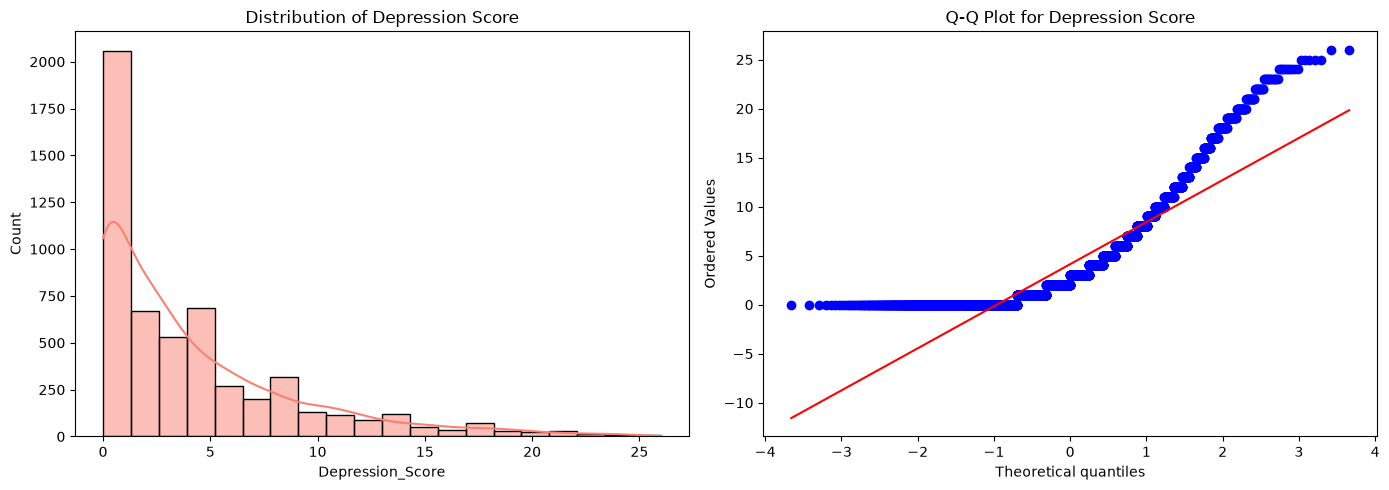

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

cols = [f'DPQ0{i}0' for i in range(1, 10)]

# Deleting rows without answers
df_dpq = df_dpq.dropna(subset=cols)
df_dpq['Depression_Score'] = df_dpq[cols].sum(axis=1)

# Drawing Charts
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
sns.histplot(df_dpq['Depression_Score'], kde=True, bins=20, ax=ax[0], color='salmon')
ax[0].set_title('Distribution of Depression Score')

# 2. Q-Q Plot
stats.probplot(df_dpq['Depression_Score'], dist="norm", plot=ax[1])
ax[1].set_title('Q-Q Plot for Depression Score')

plt.tight_layout()
plt.show()



In [2]:
import pandas as pd

file_path = r'D:\Uni\ترم 5\Statistics\Projects\cleaned_data_phase1.csv'
df = pd.read_csv(file_path)

mean_val = df['PHQ9_Score'].mean()
var_val = df['PHQ9_Score'].var()
std_val = df['PHQ9_Score'].std()

print(f"Mean: {mean_val:.4f}")
print(f"Variance: {var_val:.4f}")
print(f"Std Dev: {std_val:.4f}")


Mean: 5.0379
Variance: 26.7239
Std Dev: 5.1695


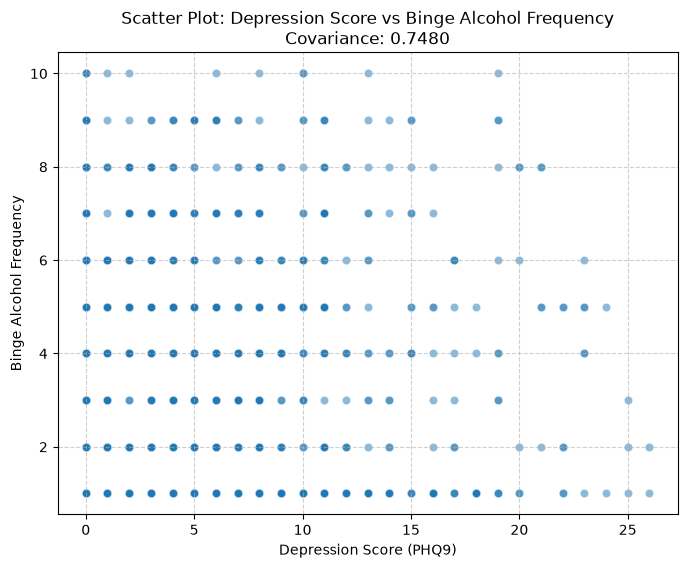

Covariance: 0.7480


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

file_path = r'D:\Uni\ترم 5\Statistics\Projects\cleaned_data_phase1.csv'
df = pd.read_csv(file_path)

# Calculating Covariance
covariance = df['PHQ9_Score'].cov(df['Binge_Freq_Y'])

# Drawing Scatter Plot
plt.figure(figsize=(8, 6))
sns.scatterplot(x='PHQ9_Score', y='Binge_Freq_Y', data=df, alpha=0.5)
plt.title(f'Scatter Plot: Depression Score vs Binge Alcohol Frequency\nCovariance: {covariance:.4f}')
plt.xlabel('Depression Score (PHQ9)')
plt.ylabel('Binge Alcohol Frequency')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print(f"Covariance: {covariance:.4f}")


In [10]:
# 1. Chance of depression in genders
prob_gender = df_final.groupby('RIAGENDR')['Depression_Event_A'].mean()
print("Chance of depression among genders:\n", prob_gender)

# 2. Chance of depression among people under and above 40:
df_final['Age_Group'] = pd.cut(df_final['RIDAGEYR'], bins=[17, 40, 100], labels=['Younger_than_40', '40_or_older'])
prob_age = df_final.groupby('Age_Group')['Depression_Event_A'].mean()
print("\nChance of depression among age groups:\n", prob_age)


Chance of depression among genders:
 RIAGENDR
1.0    0.134393
2.0    0.205742
Name: Depression_Event_A, dtype: float64

Chance of depression among age groups:
 Age_Group
Younger_than_40    0.195008
40_or_older        0.143068
Name: Depression_Event_A, dtype: float64


In [11]:
import numpy as np

# Set the subgroup size
n = 50 
p_empirical = df_final['Depression_Event_A'].mean()

# Randomly shuffle data to ensure independent subgroups
shuffled_data = df_final['Depression_Event_A'].sample(frac=1, random_state=42).reset_index(drop=True)
num_subsamples = len(shuffled_data) // n

# Extract the count of depression events for each subgroup
counts = [shuffled_data.iloc[i*n : (i+1)*n].sum() for i in range(num_subsamples)]

# Perform the comparative calculations
mean_observed = np.mean(counts)
var_observed = np.var(counts, ddof=1)

mean_theoretical = n * p_empirical
var_theoretical = n * p_empirical * (1 - p_empirical)

# Print the comparison
print(f"Sample size per group (n): {n}")
print(f"Number of subgroups: {num_subsamples}")
print(f"Probability (p): {p_empirical:.4f}")
print(f"Theoretical Mean (n*p): {mean_theoretical:.4f}")
print(f"Empirical Mean: {mean_observed:.4f}")
print(f"Theoretical Variance (n*p*(1-p)): {var_theoretical:.4f}")
print(f"Empirical Variance: {var_observed:.4f}")


Sample size per group (n): 50
Number of subgroups: 26
Probability (p): 0.1683
Theoretical Mean (n*p): 8.4155
Empirical Mean: 8.4231
Theoretical Variance (n*p*(1-p)): 6.9991
Empirical Variance: 11.7738


In [12]:
import numpy as np

# 1. Unweighted empirical probability (Sample Proportion)
unweighted_p = df_final['Depression_Event_A'].mean()

# 2. Weighted empirical probability (Population Proportion Estimate)
# Using survey weight column: WTMECPRP
weighted_p = np.average(
    df_final['Depression_Event_A'], 
    weights=df_final['WTMECPRP']
)

# 3. Output results
print(f"Unweighted Sample Proportion (P_sample): {unweighted_p:.4f} ({unweighted_p * 100:.2f}%)")
print(f"Weighted Population Estimate (P_population): {weighted_p:.4f} ({weighted_p * 100:.2f}%)")
print(f"Absolute Difference: {abs(weighted_p - unweighted_p):.4f}")
print(f"Relative Difference: {(abs(weighted_p - unweighted_p) / unweighted_p) * 100:.2f}%")


Unweighted Sample Proportion (P_sample): 0.1683 (16.83%)
Weighted Population Estimate (P_population): 0.1506 (15.06%)
Absolute Difference: 0.0177
Relative Difference: 10.49%
